In [74]:
import os
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from lightgbm import LGBMRegressor

from xgboost import XGBRegressor

import utils.prediction_utils as pred
from utils import dictionaries as dictionary
from utils.logger import setup_logger

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

# Suppress all warnings
warnings.filterwarnings('ignore')

In [83]:
## FUNCTIONS
logger = setup_logger('logs/')

def prep_dataframe(df_bereik: pd.DataFrame) -> pd.DataFrame:


    df = df_bereik[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                    "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                    "ster_1+"]].reset_index(drop=True)

    df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                         columns='daypart', fill_value=0.0,
                         values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                 'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())

    df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

    # Convert start_date and end_date to datetime objects and calculate required values
    df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
    df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

    # Apply function to create extra columns
    df['timef_start_month'] = df['start_date'].dt.month
    df['timef_end_month'] = df['end_date'].dt.month
    df['timef_start_year'] = df['start_date'].dt.year
    df['timef_end_year'] = df['end_date'].dt.year
    df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
    df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
    df['timef_start_day'] = df['start_date'].dt.day
    df['timef_end_day'] = df['end_date'].dt.day
    df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

    df['timef_start_season'] = df['timef_start_month'].apply(get_season)
    df['timef_end_season'] = df['timef_end_month'].apply(get_season)

    # Calculate total overlap with olympics and WK/EK
    df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
    df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

    df = df.sort_values(by='start_date')
    # Create a new column 'data_type' indicating old or new
    df['data_type'] = pd.cut(df['start_date'], bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max], labels=[0, 1])

    return df

def create_preprocessor(numerical_cols, categorical_cols, boolean_cols, scaling=True):
    """
    Create a ColumnTransformer with specified transformations for numerical, categorical, and boolean columns.
    """

    # Preprocessing for numerical data: impute missing values and optionally scale
    numerical_transformer_steps = [('imputer', SimpleImputer(strategy='mean'))]
    if scaling:
        numerical_transformer_steps.append(('scaler', StandardScaler()))

    numerical_transformer = Pipeline(steps=numerical_transformer_steps)

    # Preprocessing for categorical data: impute missing values and one-hot encode
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))])

    # Preprocessing for boolean data: convert to integers (0 or 1)
    boolean_transformer = Pipeline(steps=[
        ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
        ('imputer', SimpleImputer(strategy='most_frequent'))])

    # Combine preprocessing steps
    transformers = []
    transformers.append(('num', numerical_transformer, numerical_cols))
    transformers.append(('cat', categorical_transformer, categorical_cols))
    transformers.append(('bool', boolean_transformer, boolean_cols))

    preprocessor = ColumnTransformer(transformers=transformers)

    return preprocessor

def grid_search_models(X_train, X_test, y_train, y_test, models):
    # Initialize lists to store results
    results = []
    best_model = None
    best_score = float('-inf')
    best_params = None

    # Initialize lists to store metrics
    models_data = {
        'Model': [],
        'Parameters': [],
        'R2 Train': [],
        'R2 Test': [],
        'MSE Train': [],
        'MSE Test': [],
        'MAE Train': [],
        'MAE Test': []
    }

    # Store GridSearchCV objects
    grid_search_objects = []

    # TimeSeriesSplit cross-validator
    tscv = TimeSeriesSplit(n_splits=5)

     # Calculate total number of iterations
    total_iterations = sum(len(ParameterGrid(model_info['params'])) for model_info in models) * tscv.get_n_splits(X_train)

    # Create a progress bar
    pbar = tqdm(total=total_iterations, desc="Grid Search Progress")

    # Perform GridSearchCV for each model
    for model_info in models:
        # Create pipeline with preprocessor and model
        pipeline = Pipeline(steps=[
            ('preprocessor', model_info['preprocessor']),
            ('model', model_info['model'])
        ])

        # Create GridSearchCV
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=model_info['params'],
            cv=tscv,
            scoring='neg_mean_squared_error',
            n_jobs=-1,
            return_train_score=True,
            verbose=2
        )

        # Fit GridSearchCV
        grid_search.fit(X_train, y_train)
        pbar.update(len(ParameterGrid(model_info['params'])) * tscv.get_n_splits(X_train))

        # Store the GridSearchCV object
        grid_search_objects.append(grid_search)

        # Get results and metrics
        results_df = pd.DataFrame(grid_search.cv_results_)
        results.append(results_df)

        # Best model and parameters
        if grid_search.best_score_ > best_score:
            best_score = grid_search.best_score_
            best_model = grid_search.best_estimator_
            best_params = grid_search.best_params_

        # Predictions on train and test sets
        y_train_pred = grid_search.predict(X_train)
        y_test_pred = grid_search.predict(X_test)

        # Calculate metrics
        r2_train = r2_score(y_train, y_train_pred)
        r2_test = r2_score(y_test, y_test_pred)
        mse_train = mean_squared_error(y_train, y_train_pred)
        mse_test = mean_squared_error(y_test, y_test_pred)
        mae_train = mean_absolute_error(y_train, y_train_pred)
        mae_test = mean_absolute_error(y_test, y_test_pred)

        # Store metrics in dictionary
        models_data['Model'].append(model_info['name'])
        models_data['Parameters'].append(grid_search.best_params_)
        models_data['R2 Train'].append(r2_train)
        models_data['R2 Test'].append(r2_test)
        models_data['MSE Train'].append(mse_train)
        models_data['MSE Test'].append(mse_test)
        models_data['MAE Train'].append(mae_train)
        models_data['MAE Test'].append(mae_test)

     # Close the progress bar
    pbar.close()

    # Create DataFrame from models_data
    models_df = pd.DataFrame(models_data)

    # Print best model and parameters
    print(f"Best Model: {best_model}")
    print(f"Best Parameters: {best_params}")

    # Ensure X_test is properly transformed before extracting SHAP values
    X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test)

    # Extract SHAP values if the best model is a tree-based model
    shap_values = None
    if isinstance(best_model.named_steps['model'], XGBRegressor):
        explainer = shap.Explainer(best_model.named_steps['model'])
        shap_values = explainer(X_test_transformed)
        print("SHAP values extracted for XGBoost model.")
    elif isinstance(best_model.named_steps['model'], LGBMRegressor):
        explainer = shap.Explainer(best_model.named_steps['model'])
        shap_values = explainer(X_test_transformed)
        print("SHAP values extracted for LightGBM model.")
    else:
        print("The best model is not a tree-based model. SHAP values cannot be extracted.")

    return results, best_model, best_params, models_df, grid_search_objects, shap_values

def query_to_df(query):
    engine = create_sql_alchemy_engine()
    df_query = pd.read_sql_query(query, engine)

    return df_query

def create_sql_alchemy_engine():
    from sqlalchemy import create_engine
    from urllib.parse import quote_plus
    """
    Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
    """
    quoted = quote_plus(
        "Driver={ODBC+Driver+17+for+SQL+Server};"
        "Server=tcp:stercampsql.database.windows.net;"
        "Database=SterCampNew;"
        "uid=stercampadmin;"
        f"pwd={os.getenv('SQLDB')}"
    )
    alchemy_con = "mssql+pyodbc:///?odbc_connect={}".format(quoted)
    engine = create_engine(alchemy_con)

    return engine

# Fetch and preprocess data
def fetch_and_prep_data(query):
    try:
        df = query_to_df(query)
        df = prep_dataframe(df)
    except Exception as e:
        print(f"Error executing query: {str(e)}")
        return None
    return df

# Split data into train and test sets
def split_data(df, test_set_date):
    train_data = df[df['start_date'] < test_set_date]
    test_data = df[df['start_date'] >= test_set_date]
    return train_data, test_data

# Prepare features and target
def prepare_features_and_target(train_data, test_data, features, target):
    X_train = train_data[features]
    y_train = train_data[target]
    X_test = test_data[features]
    y_test = test_data[target]
    return X_train, y_train, X_test, y_test

def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'

def filter_outliers(df):

    q_low = df['ster_grp_total'].quantile(0.01)
    q_hi  = df['ster_grp_total'].quantile(0.99)
    df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

    q_low = df['ster_1+_total'].quantile(0.01)
    q_hi  = df['ster_1+_total'].quantile(0.99)
    df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

    return df

In [105]:
# Variables to tweak
TEST_SET_DATE = pd.to_datetime('2024-05-01')
CUT_OFF_DATE = '2023-01-01'
TARGET_GROUPS = ['25-67']

# Convert the list to a format suitable for SQL IN clause
formatted_target_groups = "', '".join(TARGET_GROUPS)
formatted_target_groups = f"('{formatted_target_groups}')"

# SQL Query
def construct_query():
    query = f'''
        SELECT b.flight_id,
               b.target_group,
               f.advertiser,
               f.product,
               f.start_date,
               f.end_date,
               b.campaign_duration,
               b.daypart,
               f.mock_campaign,
               f.alcohol_kansspelen,
               b.total_grp,
               b.ster_grp,
               b.regio_grp,
               b.npo1_grp,
               b.npo2_grp,
               b.npo3_grp,
               b.[ster_1+]
        FROM [dbo].[tv.bereik_ster] b
        LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
        WHERE b.ster_grp > 0 AND target_group IN {formatted_target_groups}
          AND start_date >= '{CUT_OFF_DATE}'
        ORDER BY start_date
    '''
    return query
query = construct_query()
df = fetch_and_prep_data(query)


In [106]:
print(len(df))
df = filter_outliers(df)
print(len(df))

9843
9447


In [107]:
NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime', 'npo1_grp_total',
                  'npo2_grp_daynight', 'npo2_grp_primetime', 'npo2_grp_total',
                  'npo3_grp_daynight', 'npo3_grp_primetime', 'npo3_grp_total',
                  'regio_grp_daynight', 'regio_grp_primetime', 'regio_grp_total',
                  'timef_start_month', 'timef_end_month', 'timef_start_week', 'timef_end_week',
                  'timef_start_year', 'timef_end_year', 'timef_start_day', 'timef_end_day', 'timef_duration_days',
                  'timef_olympic_period_overlap', 'timef_football_period_overlap'
                  ]

CATEGORICAL_COLS = [
                    'timef_start_season', 'timef_end_season'
                    ]

BOOLEAN_COLS = ['alcohol_kansspelen', 'data_type']

FEATURES = NUMERICAL_COLS + CATEGORICAL_COLS + BOOLEAN_COLS

TARGET = 'ster_1+_total'

In [108]:
train_data, test_data = split_data(df, TEST_SET_DATE)
X_train, y_train, X_test, y_test = prepare_features_and_target(train_data, test_data, FEATURES, TARGET)

In [109]:
X_train.head(5)
y_train.head(5)

,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,...,timef_end_year,timef_start_day,timef_end_day,timef_duration_days,timef_olympic_period_overlap,timef_football_period_overlap,timef_start_season,timef_end_season,alcohol_kansspelen,data_type
7984,0.00,7.92,7.92,0.38,2.40,2.78,0.00,0.95,0.95,0.0,...,2023,1,6,6,0,0,Winter,Winter,False,0
2778,48.40,62.23,110.63,22.51,26.67,49.18,0.89,1.13,2.02,0.0,...,2023,1,9,9,0,0,Winter,Winter,False,0
8468,0.00,51.24,51.24,0.00,0.00,0.00,0.00,8.49,8.49,0.0,...,2023,1,14,14,0,0,Winter,Winter,False,0
7496,5.18,94.82,100.00,2.11,19.14,21.24,1.14,3.18,4.32,0.0,...,2023,1,18,49,0,0,Winter,Winter,False,0
8380,0.52,18.44,18.95,0.22,8.80,9.02,1.59,1.40,2.99,0.0,...,2023,1,26,26,0,0,Winter,Winter,False,0


7984    10.06
2778    53.17
8468    23.28
7496    45.83
8380    21.29
Name: ster_1+_total, dtype: float64

In [114]:
def create_models(preprocessor_scaled, preprocessor_unscaled):
    models = [
        {
            'name': 'XGB without scaling',
            'model': XGBRegressor(objective='reg:squarederror'),
            'params': {
                'model__colsample_bytree': [0.8, 1.0],
                'model__gamma': [0.4, 0.6, 0.8],
                'model__learning_rate': [0.01, 0.05, 0.1],
                'model__max_depth': [5, 10, 15],
                'model__min_child_weight': [1, 5, 10],
                'model__n_estimators': [200, 400, 600],
                'model__reg_alpha': [0, 0.05, 0.1],
                'model__reg_lambda': [1, 2, 3],
                'model__subsample': [0.3, 0.6, 0.9],
                'model__random_state': [42]
            },
            'preprocessor': preprocessor_unscaled
        },
        {
            'name': 'LGBM without scaling',
            'model': LGBMRegressor(objective='regression'),
            'params': {
                'model__num_leaves': [30, 50, 70],
                'model__max_depth': [3, 5, 8],
                'model__learning_rate': [0.01, 0.05, 0.1],
                'model__n_estimators': [200, 400, 600],
                'model__subsample': [0.7, 0.8, 0.9],
                'model__colsample_bytree': [0.7, 0.8, 1.0],
                'model__reg_alpha': [0, 0.1, 0.3],
                'model__reg_lambda': [0, 1, 3],
                'model__random_state': [42]
            },
            'preprocessor': preprocessor_unscaled
        }
    ]

    return models

def create_minimal_models(preprocessor_scaled, preprocessor_unscaled):
    models = [
        {
            'name': 'XGB minimal',
            'model': XGBRegressor(objective='reg:squarederror', random_state=42),
            'params': {
                'model__n_estimators': [100],
                'model__max_depth': [3],
                'model__learning_rate': [0.1],
            },
            'preprocessor': preprocessor_unscaled
        },
        {
            'name': 'LGBM minimal',
            'model': LGBMRegressor(objective='regression', random_state=42),
            'params': {
                'model__n_estimators': [100],
                'model__max_depth': [3],
                'model__learning_rate': [0.1],
            },
            'preprocessor': preprocessor_unscaled
        }
    ]

    return models


preprocessor_scaled = create_preprocessor(NUMERICAL_COLS, CATEGORICAL_COLS, BOOLEAN_COLS, scaling=True)
preprocessor_unscaled = create_preprocessor(NUMERICAL_COLS, CATEGORICAL_COLS, BOOLEAN_COLS, scaling=False)
# models = create_models(preprocessor_scaled, preprocessor_unscaled)
models = create_minimal_models(preprocessor_scaled, preprocessor_unscaled)


In [113]:
# Fit and transform data
X_transformed = preprocessor_unscaled.fit_transform(X_test)

# Convert to DataFrame
num_features = len(NUMERICAL_COLS)
cat_features = list(preprocessor_unscaled.transformers_[1][1].named_steps['onehot'].get_feature_names_out(CATEGORICAL_COLS))
bool_features = BOOLEAN_COLS
all_feature_names = NUMERICAL_COLS + cat_features + bool_features

# Create DataFrame
X_transformed_df = pd.DataFrame(X_transformed, columns=all_feature_names)

# Display transformed data
X_transformed_df.head(5)

,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,...,timef_end_year,timef_start_day,timef_end_day,timef_duration_days,timef_olympic_period_overlap,timef_football_period_overlap,timef_start_season_Summer,timef_end_season_Summer,alcohol_kansspelen,data_type
0,50.00,5.54,55.55,7.56,10.66,18.21,0.00,0.66,0.66,0.25,...,2024.0,1.0,1.0,32.0,0.0,0.0,0.0,1.0,0.0,1.0
1,100.61,118.43,219.03,17.03,32.56,49.59,4.25,20.07,24.32,0.10,...,2024.0,1.0,30.0,61.0,0.0,17.0,0.0,1.0,0.0,1.0
2,319.59,0.00,319.59,55.02,79.33,134.35,0.00,0.00,0.00,0.57,...,2024.0,1.0,30.0,61.0,0.0,17.0,0.0,1.0,0.0,1.0
3,27.43,47.30,74.72,4.39,9.16,13.55,0.63,9.56,10.18,0.00,...,2024.0,1.0,1.0,32.0,0.0,0.0,0.0,1.0,0.0,1.0
4,19.18,22.53,41.71,4.64,1.65,6.30,0.76,0.00,0.76,0.18,...,2024.0,1.0,1.0,32.0,0.0,0.0,0.0,1.0,0.0,1.0


In [115]:
logger.info('Start grid search at %s', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
logger.info(f'X_train.shape: {X_train.shape}, y_train.shape: {y_train.shape}, X_test.shape: {X_test.shape}, y_test.shape: {y_test.shape}')
logger.info('CUT_OFF_DATE: %s, TARGET_GROUP: %s, TEST_SET_DATE: %s', CUT_OFF_DATE, TARGET_GROUPS, TEST_SET_DATE)

# Suppress LightGBM warnings
warnings.filterwarnings('ignore', category=UserWarning, module='lightgbm')

# Run grid search
results, best_model, best_params, models_df, grid_objects, shap_values = grid_search_models(X_train, X_test, y_train, y_test, models)

logger.info('Best model: %s', best_model)
logger.info('Best parameters: %s', best_params)
logger.info("--------------------------------------------------------------------")
print(models_df)

13:42:50 - INFO - Start grid search at 2024-07-23 13:42:50
13:42:50 - INFO - X_train.shape: (8280, 27), y_train.shape: (8280,), X_test.shape: (1167, 27), y_test.shape: (1167,)
13:42:50 - INFO - CUT_OFF_DATE: 2023-01-01, TARGET_GROUP: ['25-67'], TEST_SET_DATE: 2024-05-01 00:00:00


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002025 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3196
[LightGBM] [Info] Number of data points in the train set: 8280, number of used features: 29
[LightGBM] [Info] Start training from score 25.020885
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

13:44:04 - INFO - Best model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['npo1_grp_daynight',
                                                   'npo1_grp_primetime',
                                                   'npo1_grp_total',
                                                   'npo2_grp_daynight',
                                                   'npo2_grp_primetime',
                                                   'npo2_grp_total',
                                                   'npo3_grp_daynight',
                                                   'npo3_grp_primetime',
                                                   'npo3_grp_total',
                                                   'regio_grp_daynight',


SHAP values extracted for XGBoost model.
          Model                                         Parameters  R2 Train  \
0   XGB minimal  {'model__learning_rate': 0.1, 'model__max_dept...  0.945196   
1  LGBM minimal  {'model__learning_rate': 0.1, 'model__max_dept...  0.945157   

    R2 Test  MSE Train   MSE Test  MAE Train  MAE Test  
0  0.805124  10.764474  46.201160   2.525251  4.734092  
1  0.811266  10.772082  44.745022   2.519548  4.632925  


In [116]:
models_df

,Model,Parameters,R2 Train,R2 Test,MSE Train,MSE Test,MAE Train,MAE Test
0,XGB minimal,"{'model__learning_rate': 0.1, 'model__max_dept...",0.945196,0.805124,10.764474,46.201160,2.525251,4.734092
1,LGBM minimal,"{'model__learning_rate': 0.1, 'model__max_dept...",0.945157,0.811266,10.772082,44.745022,2.519548,4.632925


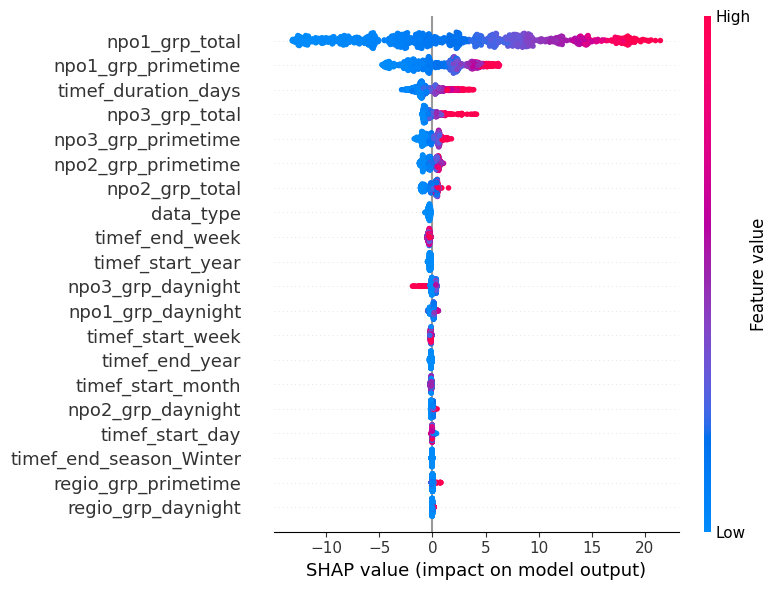

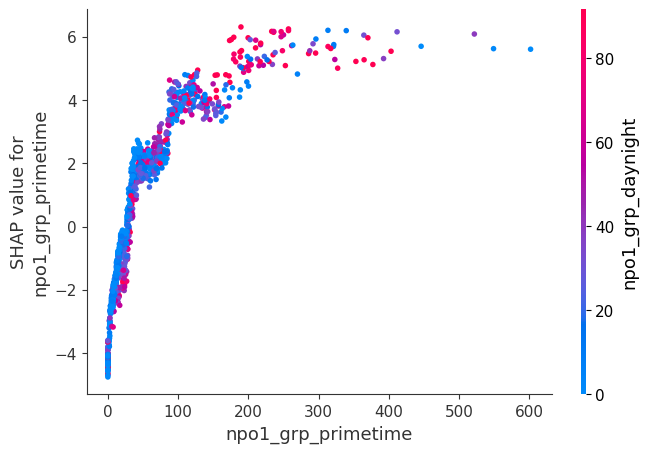

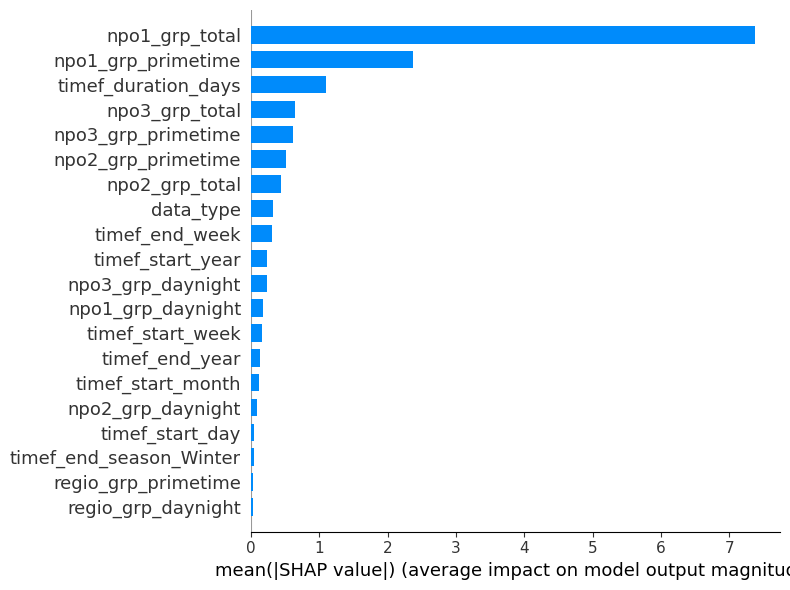

In [117]:
plt.set_loglevel (level = 'warning')

def get_feature_names(preprocessor, numerical_cols, categorical_cols, boolean_cols):
    feature_names = []

    # Get numerical feature names
    if 'num' in preprocessor.named_transformers_:
        feature_names += numerical_cols

    # Get categorical feature names
    if 'cat' in preprocessor.named_transformers_:
        encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
        cat_feature_names = encoder.get_feature_names_out(categorical_cols)
        feature_names += cat_feature_names.tolist()

    # Get boolean feature names
    if 'bool' in preprocessor.named_transformers_:
        feature_names += boolean_cols

    return feature_names


def visualize_shap_values(shap_values, X_test_transformed, feature_names):
    if shap_values is None:
        print("No SHAP values to visualize.")
        return

    # Convert to DataFrame for better handling of feature names
    X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

    # Summary plot
    shap.summary_plot(shap_values, X_test_transformed_df, plot_size=[8,6])

    # Check if SHAP values are in the right format for dependence plot
    if isinstance(shap_values, shap.Explanation):
        # Dependence plot (example for the first feature)
        shap.dependence_plot(1, shap_values.values, X_test_transformed_df, feature_names=feature_names)
    else:
        print("SHAP values are not in the expected format for dependence plot.")

    # # Bar plot of feature importances
    shap.summary_plot(shap_values, X_test_transformed_df, plot_type="bar", plot_size=[8,6])

X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test)
feature_names = get_feature_names(best_model.named_steps['preprocessor'], NUMERICAL_COLS, CATEGORICAL_COLS, BOOLEAN_COLS)
visualize_shap_values(shap_values, X_test_transformed, feature_names)

In [118]:
# Convert SHAP values to a DataFrame
shap_df = pd.DataFrame(shap_values.values, columns=feature_names)
shap_importance = shap_df.abs().mean().sort_values(ascending=False)
shap_importance

npo1_grp_total                   7.374780
npo1_grp_primetime               2.372419
timef_duration_days              1.107048
npo3_grp_total                   0.646883
npo3_grp_primetime               0.618907
npo2_grp_primetime               0.519463
npo2_grp_total                   0.437114
data_type                        0.322406
timef_end_week                   0.314569
timef_start_year                 0.241105
npo3_grp_daynight                0.235514
npo1_grp_daynight                0.171078
timef_start_week                 0.156940
timef_end_year                   0.130684
timef_start_month                0.117889
npo2_grp_daynight                0.093190
timef_start_day                  0.047335
timef_end_season_Winter          0.043927
regio_grp_primetime              0.031514
regio_grp_daynight               0.026601
timef_start_season_Summer        0.014049
alcohol_kansspelen               0.010974
timef_end_month                  0.010574
regio_grp_total                  0

In [ ]:
# Best Parameters: {'model__colsample_bytree': 1.0, 'model__gamma': 0.4, 'model__learning_rate': 0.01, 'model__max_depth': 5, 'model__min_child_weight': 5, 'model__n_estimators': 500, 'model__reg_alpha': 0, 'model__reg_lambda': 2, 'model__subsample': 0.6}
# Best Parameters: {'model__colsample_bytree': 0.8, 'model__gamma': 0.6, 'model__learning_rate': 0.01, 'model__max_depth': 10, 'model__min_child_weight': 8, 'model__n_estimators': 400, 'model__random_state': 42, 'model__reg_alpha': 0.05, 'model__reg_lambda': 2, 'model__subsample': 0.3}

In [102]:
# Assuming you have a DataFrame 'results_df' from your grid search
print(models_df[['Model', 'Parameters', 'R2 Train', 'R2 Test', 'MSE Train', 'MSE Test', 'MAE Train', 'MAE Test']])

# Check for overfitting by comparing train and test performance
for index, row in models_df.iterrows():
    print(f"Model: {row['Model']}")
    print(f"Train R2: {row['R2 Train']:.4f}, Test R2: {row['R2 Test']:.4f}")
    print(f"Train MSE: {row['MSE Train']:.4f}, Test MSE: {row['MSE Test']:.4f}")
    print(f"Train MAE: {row['MAE Train']:.4f}, Test MAE: {row['MAE Test']:.4f}")
    print("\n")

                  Model                                         Parameters  \
0   XGB without scaling  {'model__colsample_bytree': 0.8, 'model__gamma...   
1  LGBM without scaling  {'model__colsample_bytree': 0.7, 'model__learn...   

   R2 Train   R2 Test  MSE Train   MSE Test  MAE Train  MAE Test  
0  0.968680  0.802976   5.804821  50.976472   1.857285  4.992548  
1  0.952288  0.796956   8.842766  52.534031   2.302152  5.067999  
Model: XGB without scaling
Train R2: 0.9687, Test R2: 0.8030
Train MSE: 5.8048, Test MSE: 50.9765
Train MAE: 1.8573, Test MAE: 4.9925


Model: LGBM without scaling
Train R2: 0.9523, Test R2: 0.7970
Train MSE: 8.8428, Test MSE: 52.5340
Train MAE: 2.3022, Test MAE: 5.0680


